# Laboratory 3

**Before you start:** 
1. Create conda/mamba environment from `environment.yaml`

In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
import matplotlib.pyplot as plt

## 1. Why do we use scaling by $\sqrt{d_k}$ in dot-product attention?

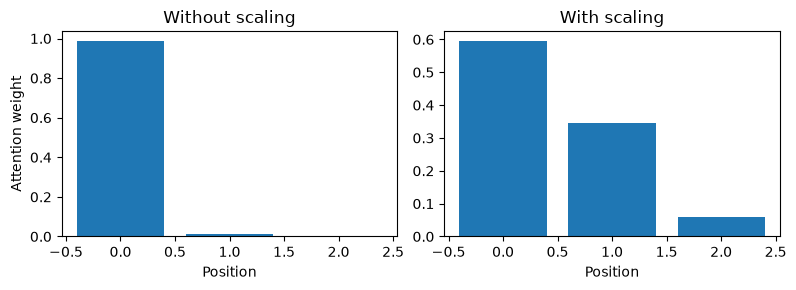

In [2]:
torch.manual_seed(42)

# "n" keys (positions), each with dimension d_k
d_k = 64
n_positions = 3

Q = torch.randn(1, d_k)
K = torch.randn(n_positions, d_k)

# Dot-product attention scores
scores = Q @ K.T

# Attention without scaling
att_no_scale = F.softmax(scores, dim=-1)

# Attention with scaling
att_scaled = F.softmax(scores / (d_k ** 0.5), dim=-1)

# Visualization
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.bar(range(n_positions), att_no_scale.detach().numpy()[0])
plt.title("Without scaling")
plt.xlabel("Position")
plt.ylabel("Attention weight")

plt.subplot(1, 2, 2)
plt.bar(range(n_positions), att_scaled.detach().numpy()[0])
plt.title("With scaling")
plt.xlabel("Position")

plt.tight_layout()
plt.show()

### Comments

- With scaling, attention is more distributed
- The model can better adjust its attention weights during training

## 2. How scaling influence training?

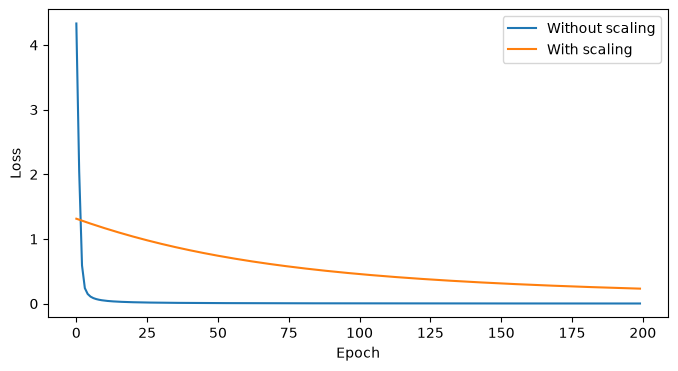

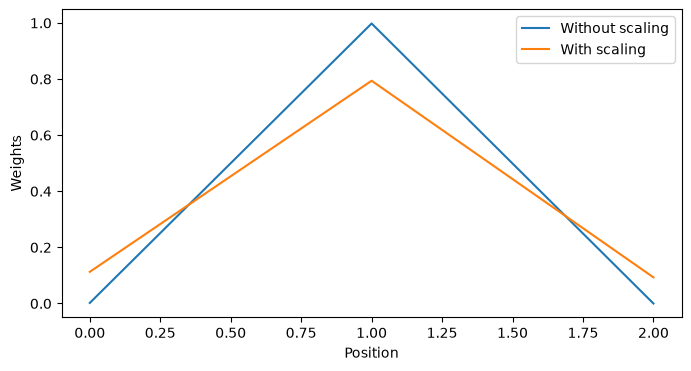

In [10]:
torch.manual_seed(42)

d_k = 64
n_positions = 3

# Learnable query and keys
class SimpleAttention(nn.Module):
    def __init__(self, scale):
        super().__init__()
        self.q = nn.Parameter(torch.randn(1, d_k))
        self.k = nn.Parameter(torch.randn(n_positions, d_k))
        self.scale = scale

    def forward(self):
        scores = self.q @ self.k.T

        if self.scale:
            scores = scores / (d_k ** 0.5)

        weights = F.softmax(scores, dim=-1)
        return weights


def train_model(scale):
    model = SimpleAttention(scale)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

    losses = []

    for epoch in range(200):
        optimizer.zero_grad()

        weights = model()

        # We want position 1 to receive all attention (2nd index)
        loss = -torch.log(weights[0, 1] + 1e-9)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    return losses, model().detach(),


loss_no_scale, weights_no_scale = train_model(False)
loss_scaled, weights_scaled = train_model(True)

# Plot learning curves
plt.figure(figsize=(8, 4))
plt.plot(loss_no_scale, label="Without scaling")
plt.plot(loss_scaled, label="With scaling")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot weights
plt.figure(figsize=(8, 4))
plt.plot(weights_no_scale[0].numpy(), label="Without scaling")
plt.plot(weights_scaled[0].numpy(), label="With scaling")
plt.xlabel("Position")
plt.ylabel("Weights")
plt.legend()
plt.show()

### Comments

- Did we expect this? What actually happened?
- What about scaling by $d_k$?

## Why do we need positonal embedding?

In [12]:
torch.manual_seed(42)

# Three token embeddings
X = torch.randn(3, 4)

# A simple self-attention layer
def self_attention(X):
    Q = X
    K = X
    V = X

    scores = Q @ K.T
    weights = F.softmax(scores, dim=-1)

    # Output matrix
    return weights @ V


# Original sequence
output1 = self_attention(X)

# Shuffle the tokens
permutation = torch.tensor([2, 0, 1])
inverse_permutation = torch.argsort(permutation)
X_shuffled = X[permutation]

output2 = self_attention(X_shuffled)

# Compare outputs
print("Original output:")
print(output1)

print("\nShuffled output:")
print(output2)

print("\nShuffled output (restored to original order):")
print(output2[inverse_permutation])

print("\nAre outputs identical?")
print(torch.allclose(output1, output2[inverse_permutation]))

Original output:
tensor([[ 0.0260,  0.1091,  0.8539,  0.2598],
        [-1.1185, -0.1852,  2.2030, -0.6346],
        [ 0.1448,  0.1491,  0.7536,  0.3953]])

Shuffled output:
tensor([[ 0.1448,  0.1491,  0.7536,  0.3953],
        [ 0.0260,  0.1091,  0.8539,  0.2598],
        [-1.1185, -0.1852,  2.2030, -0.6346]])

Shuffled output (restored to original order):
tensor([[ 0.0260,  0.1091,  0.8539,  0.2598],
        [-1.1185, -0.1852,  2.2030, -0.6346],
        [ 0.1448,  0.1491,  0.7536,  0.3953]])

Are outputs identical?
True


### Comments:
- Attention output is equivariant, so, practically token positions do not matter and attention weights act the same way on values
- Realistically, we should also add trainable projection matrices (not needed for demonstration)

### Now, let's add positional embedding 

In [13]:
torch.manual_seed(42)

P = torch.tensor([
    [1., 0., 0., 0.],
    [0., 1., 0., 0.],
    [0., 0., 1., 0.]
])

# Original sequence
output1 = self_attention(X + P)

# Shuffle tokens, keeping positional embeddings fixed
X_shuffled = X[permutation]
output2 = self_attention(X_shuffled + P)

print("Original output:")
print(output1)

print("\nShuffled output:")
print(output2)

print("\nShuffled output (restored to original order):")
print(output2[inverse_permutation])

print("\nAre outputs identical?")
print(torch.allclose(output1, output2[inverse_permutation]))

Original output:
tensor([[ 0.9743,  0.1963,  0.7152,  0.3843],
        [-1.1070,  0.8082,  2.2012, -0.6238],
        [ 0.0504,  0.4216,  1.6388,  0.3285]])

Shuffled output:
tensor([[ 1.2768,  0.3536,  0.5619,  0.7116],
        [ 0.5619,  0.6653,  0.6970,  0.3323],
        [-1.1228, -0.1863,  3.2082, -0.6380]])

Shuffled output (restored to original order):
tensor([[ 0.5619,  0.6653,  0.6970,  0.3323],
        [-1.1228, -0.1863,  3.2082, -0.6380],
        [ 1.2768,  0.3536,  0.5619,  0.7116]])

Are outputs identical?
False


### Comments:

- Positional scheme helps the model to use also the sequence information
- This is a simplification: the one-hot encoded scheme has no natural notion of similarity

## Homework:

- Implement a simple sinusoidal embedding and check what happens if you add / multipy / concatenate it with the input $X$
- *Hint #1*: multiplication is not *a priori* wrong, but it would rescale embedding dimensions and impose an interaction between token and positional information (harder to differentiate in principle)
- *Hint #2*: concatenation is a valid alternative to addition, but increases the dimensionality and therefore changes the architecture